In [1]:
# Imports
import pandas as pd
import numpy as np
import sqlite3
import datetime
# import math
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix

In [2]:
gcm_data_path = 'MaxMustermann_glucose_20-10-2026.csv'
diary_data_path = 'glpred.db'

### Read and preprocess user Continuous Glucose Monitoring (CGM) device data
- The data is from https://www2.libreview.com/glucosereports
- The file is of following format: MaxMustermann_glucose_20-10-2026.csv
- Serves the purpose of generating labels y

In [3]:
def load_gcm_data(
    path: str,
) -> pd.DataFrame:
    df = pd.read_csv(path, header=1)
    
    # Drop rows empty in both columns and ensure an independent copy of the dataframe
    filtered_df = df.dropna(subset=['Historic Glucose mg/dL', 'Scan Glucose mg/dL'], how='all').copy()
    
    # Unify the two glucose columns into one. Since no row has both filled,
    # this is a relabel — not a Scan-over-Historic priority; the per-minute
    # mean below is what actually blends the two streams.
    filtered_df['glucose'] = filtered_df['Scan Glucose mg/dL'].combine_first(filtered_df['Historic Glucose mg/dL'])
    
    # Retain only the timestamp and the new combined glucose column
    filtered_df = filtered_df[['Device Timestamp', 'glucose']].rename(columns={'Device Timestamp': 'timestamp'})
    
    # Convert timestamp to datetime
    filtered_df['timestamp'] = pd.to_datetime(filtered_df['timestamp'], dayfirst=True)
    
    # Resample to a continuous 1-minute grid (introduces NaNs for missing minutes)
    s = (
        filtered_df.set_index('timestamp')
        .resample('1min')
        .mean()['glucose']
    )
    
    # Interpolate linearly, but only bridge gaps of at most 15 minutes
    # (i.e. at most 4 consecutive missing minutes between two real readings).
    # limit_area='inside' avoids extrapolating beyond the first/last real value.
    cgm_grid = (
        s.interpolate(method='linear', limit=14, limit_area='inside')
         .dropna()
         .reset_index()
    )

    return cgm_grid


print(load_gcm_data(gcm_data_path).iloc[195:202])

              timestamp  glucose
195 2025-09-27 03:08:00    148.2
196 2025-09-27 03:09:00    147.0
197 2025-09-27 03:10:00    145.8
198 2025-09-27 03:11:00    144.6
199 2025-09-27 03:12:00    143.4
200 2025-09-27 03:13:00    142.2
201 2025-09-27 03:14:00    141.0


##### Optional: Verify functionality

In [4]:
df = pd.read_csv(gcm_data_path, header=1)

# Drop rows empty in both columns and ensure an independent copy of the dataframe
filtered_df = df.dropna(subset=['Historic Glucose mg/dL', 'Scan Glucose mg/dL'], how='all').copy()

# Unify the two glucose columns into one. Since no row has both filled,
# this is a relabel — not a Scan-over-Historic priority; the per-minute
# mean below is what actually blends the two streams.
filtered_df['glucose'] = filtered_df['Scan Glucose mg/dL'].combine_first(filtered_df['Historic Glucose mg/dL'])

# Retain only the timestamp and the new combined glucose column
filtered_df = filtered_df[['Device Timestamp', 'glucose']].rename(columns={'Device Timestamp': 'timestamp'})

# Convert timestamp to datetime
filtered_df['timestamp'] = pd.to_datetime(filtered_df['timestamp'], dayfirst=True)

# Resample to a continuous 1-minute grid (introduces NaNs for missing minutes)
s = (
    filtered_df.set_index('timestamp')
    .resample('1min')
    .mean()['glucose']
)

# Interpolate linearly, but only bridge gaps of at most 15 minutes
# (i.e. at most 4 consecutive missing minutes between two real readings).
# limit_area='inside' avoids extrapolating beyond the first/last real value.
cgm_grid = (
    s.interpolate(method='linear', limit=14, limit_area='inside')
     .dropna()
     .reset_index()
)

print("Updated Columns:", filtered_df.columns)
print("Filtered shape:", filtered_df.shape)
print(filtered_df.sort_values(by='timestamp').reset_index(drop=True).iloc[195:202])
print("CGM grid shape:", cgm_grid.shape)
print(cgm_grid.iloc[195:202])

Updated Columns: Index(['timestamp', 'glucose'], dtype='str')
Filtered shape: (280142, 2)
              timestamp  glucose
195 2025-09-27 02:59:00    159.0
196 2025-09-27 03:04:00    153.0
197 2025-09-27 03:09:00    147.0
198 2025-09-27 03:14:00    141.0
199 2025-09-27 03:15:00    136.0
200 2025-09-27 03:16:00    135.0
201 2025-09-27 03:18:00    134.0
CGM grid shape: (556913, 2)
              timestamp  glucose
195 2025-09-27 03:08:00    148.2
196 2025-09-27 03:09:00    147.0
197 2025-09-27 03:10:00    145.8
198 2025-09-27 03:11:00    144.6
199 2025-09-27 03:12:00    143.4
200 2025-09-27 03:13:00    142.2
201 2025-09-27 03:14:00    141.0


##### Optional: Find out the time span this data ist from 

In [5]:
# Compute the time span directly on a temporary conversion without altering filtered_df
start_time = pd.to_datetime(filtered_df['timestamp'], format='%d-%m-%Y %H:%M').min()
end_time = pd.to_datetime(filtered_df['timestamp'], format='%d-%m-%Y %H:%M').max()

print(f"Dataset time span: {start_time} through {end_time}")

Dataset time span: 2025-09-26 23:53:00 through 2026-10-20 12:10:00


##### Optional: Verify row duplicates for
'''s = (
    filtered_df.set_index('timestamp')
    .resample('1min')
    .mean()['glucose']
)'''

In [6]:
df = pd.read_csv(gcm_data_path, header=1)
df['timestamp'] = pd.to_datetime(df['Device Timestamp'], dayfirst=True)

print("rows:", len(df))
print("nonzero seconds:", (df['timestamp'].dt.second != 0).sum())
print("nonzero microseconds:", (df['timestamp'].dt.microsecond != 0).sum())

gl = df.dropna(subset=['Historic Glucose mg/dL','Scan Glucose mg/dL'], how='all')
print("glucose rows:", len(gl))

# Within-stream duplicates at the same exact timestamp:
h = gl.dropna(subset=['Historic Glucose mg/dL'])
s = gl.dropna(subset=['Scan Glucose mg/dL'])
print("Historic exact-ts duplicates:", h['timestamp'].duplicated().sum())
print("Scan exact-ts duplicates:", s['timestamp'].duplicated().sum())

# Rows per minute bucket:
per_min = gl.assign(minute=gl['timestamp'].dt.floor('1min')).groupby('minute').agg(
    n_h=('Historic Glucose mg/dL','count'),
    n_s=('Scan Glucose mg/dL','count'),
)
print("max rows per bucket:", (per_min.n_h + per_min.n_s).max())
print("buckets with both:", ((per_min.n_h>0) & (per_min.n_s>0)).sum())
print("bucket-size distribution:\n", (per_min.n_h + per_min.n_s).value_counts().sort_index())

rows: 312981
nonzero seconds: 0
nonzero microseconds: 0
glucose rows: 280142
Historic exact-ts duplicates: 3
Scan exact-ts duplicates: 914
max rows per bucket: 4
buckets with both: 33834
bucket-size distribution:
 1    211008
2     34017
3       364
4         2
Name: count, dtype: int64


### Import app SQLite database from device (X_data)
- This data is generated via human inputs into an android app, from which it is fetched when the device is connected to the PC
- (currently running on madeup data)

In [7]:
def load_diary_data(
    path: str,
) -> pd.DataFrame:
    con = sqlite3.connect(path)
    diary_df = pd.read_sql_query("SELECT * from diary_table", con)
    con.close()
    
    diary_df['timestamp'] = pd.to_datetime(diary_df['date'] + " " + diary_df['time'], dayfirst=True)
    diary_df = diary_df[['timestamp', 'glucose', 'carbs', 'bolus', 'basis']]
    diary_df = diary_df.sort_values(["timestamp"]).reset_index(drop=True)
    return diary_df

print(load_diary_data(diary_data_path))
print(load_diary_data(diary_data_path).dtypes)

            timestamp  glucose  carbs  bolus  basis
0 2026-10-17 12:45:00      120    4.0      6      0
1 2026-10-18 13:45:00      130    6.0      9      0
2 2026-10-19 07:33:00      146    8.0     16     12
3 2026-10-19 12:40:00       80   10.0     10     12
4 2026-10-19 18:22:00      187    4.7     13     12
timestamp    datetime64[us]
glucose               int64
carbs               float64
bolus                 int64
basis                 int64
dtype: object


### Generate data labels (y_data)
- for SQLite database data from device
- applicable for bloodsugar values after 3, 4 and 5hours 

In [8]:
def gen_labels(
    df_diary: pd.DataFrame,
    df_cgm: pd.DataFrame,
    hours_passed: int,
    tolerance="10min",
) -> pd.DataFrame:

    # Create a working copy of the diary timestamps
    targets = df_diary[['timestamp']].copy()
    
    # Shift the timestamp by the specified prediction horizon
    targets['target_time'] = targets['timestamp'] + pd.Timedelta(hours=hours_passed)
    
    # Merge with the continuous CGM grid on the exact timestamp
    merged = pd.merge_asof(
        targets, df_cgm,
        left_on='target_time', right_on='timestamp',
        direction='nearest',
        tolerance=pd.Timedelta(tolerance),
    )
    
    column_name = f"glucose_level_{hours_passed}h"
    out = pd.DataFrame({column_name: merged['glucose']})
    return out.dropna(subset=[column_name]).reset_index(drop=True)

diary_data = load_diary_data(diary_data_path)
gcm_data = load_gcm_data(gcm_data_path)
print(gcm_data)
print(diary_data)
print(gen_labels(diary_data, gcm_data, 3))
print(gen_labels(diary_data, gcm_data, 4))
print(gen_labels(diary_data, gcm_data, 5))

                 timestamp  glucose
0      2025-09-26 23:53:00    302.0
1      2025-09-26 23:54:00    303.5
2      2025-09-26 23:55:00    309.0
3      2025-09-26 23:56:00    312.0
4      2025-09-26 23:57:00    315.0
...                    ...      ...
556908 2026-10-20 12:06:00    188.0
556909 2026-10-20 12:07:00    190.0
556910 2026-10-20 12:08:00    192.0
556911 2026-10-20 12:09:00    193.0
556912 2026-10-20 12:10:00    193.0

[556913 rows x 2 columns]
            timestamp  glucose  carbs  bolus  basis
0 2026-10-17 12:45:00      120    4.0      6      0
1 2026-10-18 13:45:00      130    6.0      9      0
2 2026-10-19 07:33:00      146    8.0     16     12
3 2026-10-19 12:40:00       80   10.0     10     12
4 2026-10-19 18:22:00      187    4.7     13     12
   glucose_level_3h
0             112.0
1             151.0
2             129.5
3             173.6
4             271.5
   glucose_level_4h
0             86.00
1             89.00
2            149.75
3            159.80
4        

##### Optional: Preprocess Data for Analysis/Visualizations

In [9]:
X_data = load_diary_data(diary_data_path)
gcm_data = load_gcm_data(gcm_data_path)

# add generated labels
y_data = gen_labels(X_data, gcm_data, 3)
X_data['glucose_3h'] = y_data

print(X_data)

def pp_analysis(
    data: pd.DataFrame,
) -> pd.DataFrame:

    pp_data = data.copy()
    
    # remove date and seperator ':'
    pp_data['timestamp'] = pp_data['timestamp'].dt.strftime('%H:%M')
    pp_data['timestamp'] = pp_data['timestamp'].str.replace(':', '')
    
    # remove leading 0s
    pp_data['timestamp'] = pp_data['timestamp'].str.lstrip('0')
    
    # transform string to int64
    pp_data['timestamp'] = pp_data['timestamp'].astype('int64')
    
    # rename column
    pp_data.rename(columns={'timestamp': 'time'}, inplace=True)

    return pp_data

print(pp_analysis(X_data))
print(pp_analysis(X_data).dtypes)

            timestamp  glucose  carbs  bolus  basis  glucose_3h
0 2026-10-17 12:45:00      120    4.0      6      0       112.0
1 2026-10-18 13:45:00      130    6.0      9      0       151.0
2 2026-10-19 07:33:00      146    8.0     16     12       129.5
3 2026-10-19 12:40:00       80   10.0     10     12       173.6
4 2026-10-19 18:22:00      187    4.7     13     12       271.5
   time  glucose  carbs  bolus  basis  glucose_3h
0  1245      120    4.0      6      0       112.0
1  1345      130    6.0      9      0       151.0
2   733      146    8.0     16     12       129.5
3  1240       80   10.0     10     12       173.6
4  1822      187    4.7     13     12       271.5
time            int64
glucose         int64
carbs         float64
bolus           int64
basis           int64
glucose_3h    float64
dtype: object


##### Optional: Vizualize/Analyze Data Training Data
- artifact of the past (when I wasnt good at this)
- very sloppy way of doing it

Visualizing iit data.. 


----- iit data head -----
   time  glucose  carbs  bolus  basis  glucose_3h
0  1245      120    4.0      6      0       112.0
1  1345      130    6.0      9      0       151.0
2   733      146    8.0     16     12       129.5
3  1240       80   10.0     10     12       173.6
4  1822      187    4.7     13     12       271.5


----- Data info -----
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   time        5 non-null      int64  
 1   glucose     5 non-null      int64  
 2   carbs       5 non-null      float64
 3   bolus       5 non-null      int64  
 4   basis       5 non-null      int64  
 5   glucose_3h  5 non-null      float64
dtypes: float64(2), int64(4)
memory usage: 372.0 bytes
None


----- Data Description -----
              time     glucose      carbs      bolus      basis  glucose_3h
count     5.000000    5.000000   5.00000

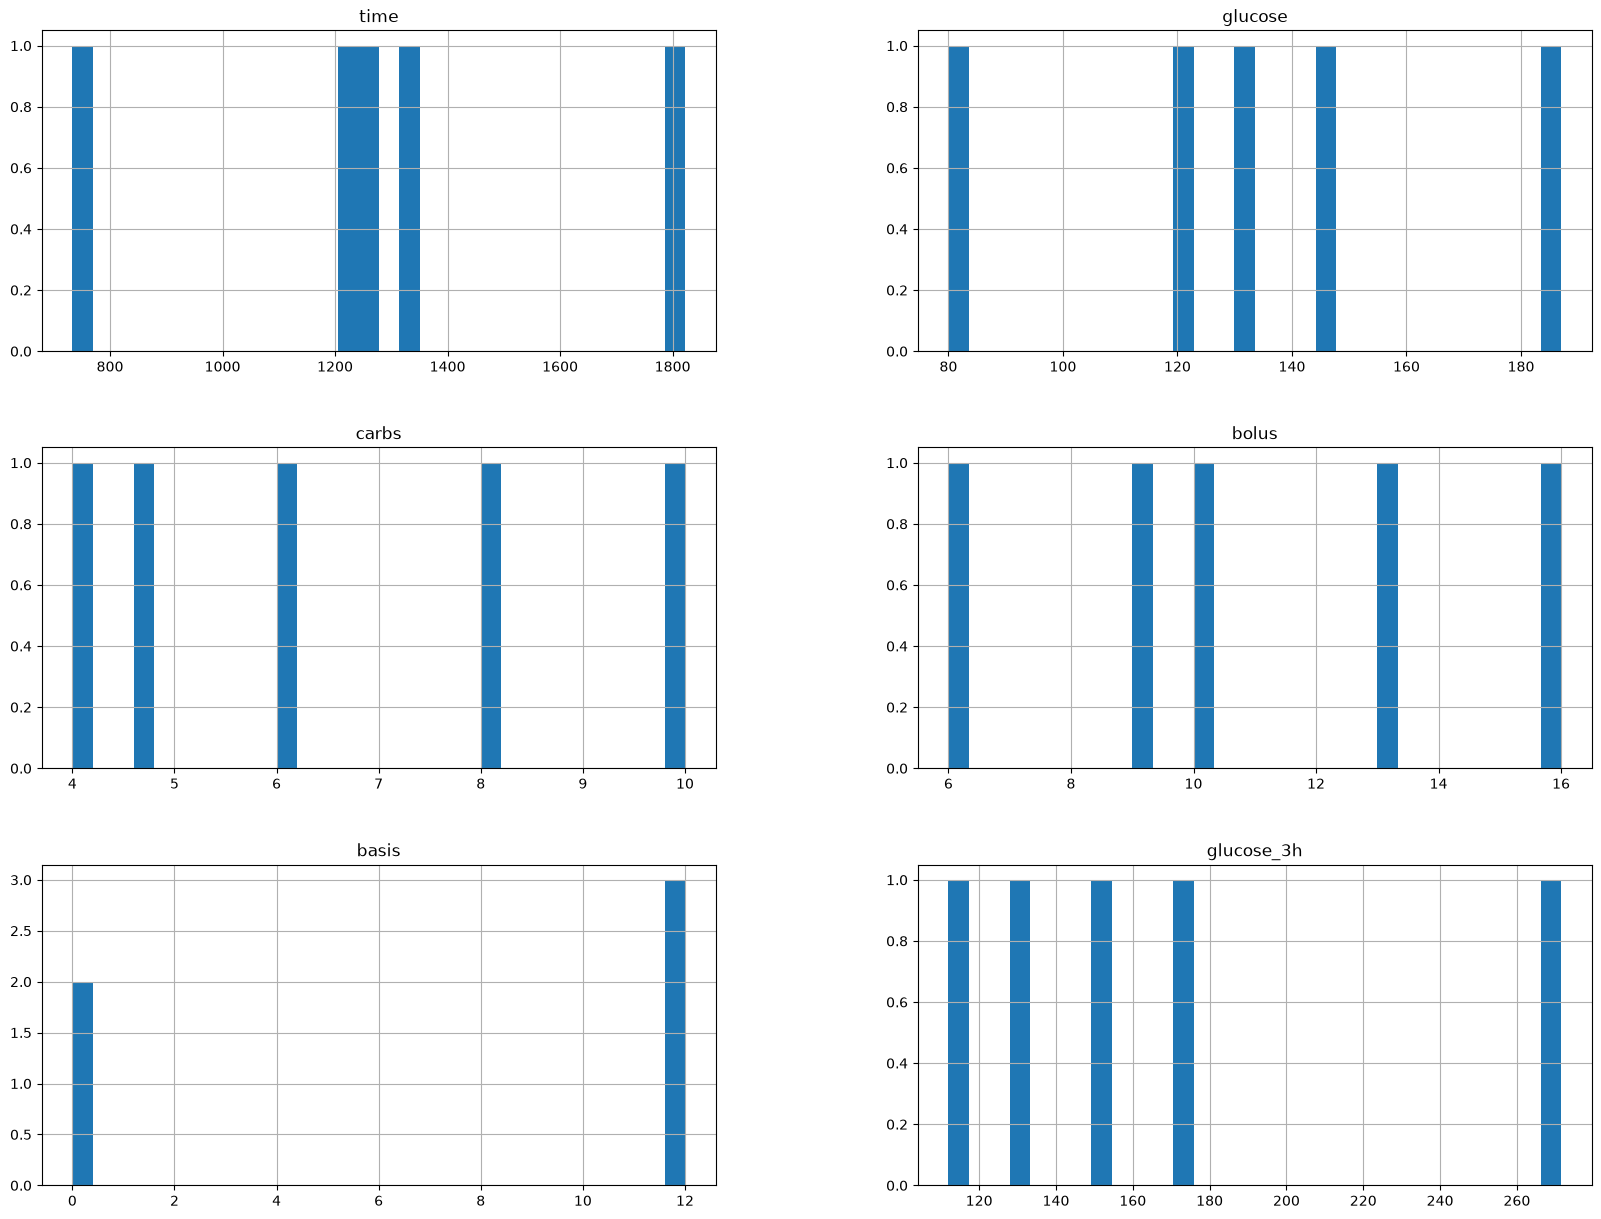



Plotting Time and glucose level after 3h as Ccatter Plot..


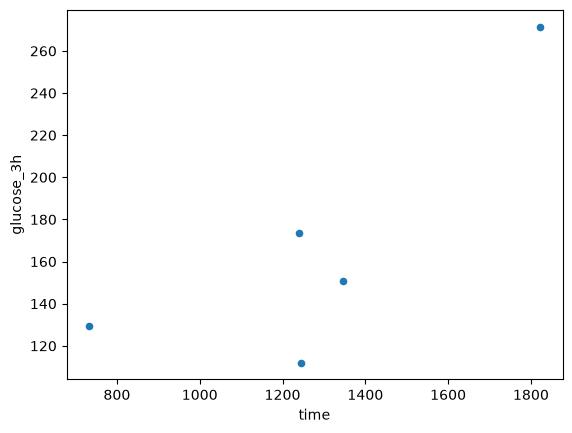



----- Correlation Matrix -----
glucose_3h    1.000000
time          0.802692
glucose       0.571406
basis         0.525690
bolus         0.336109
carbs        -0.123177
Name: glucose_3h, dtype: float64


Plotting Correlations..


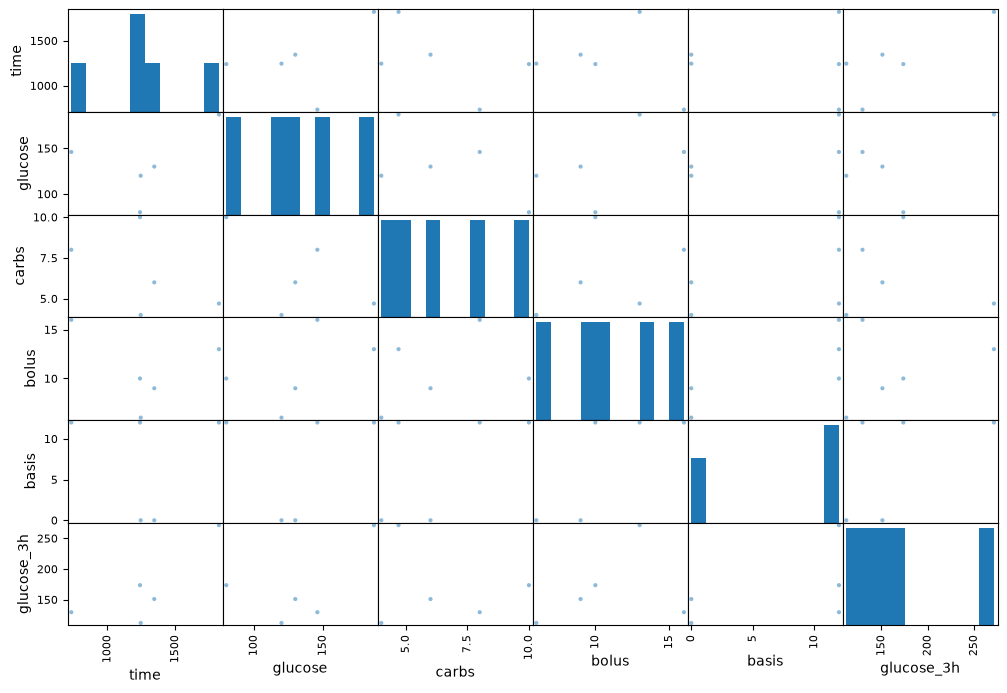

In [10]:
def analyze_data(iit_data):
    print("\n\n----- iit data head -----")
    print(iit_data.head())
    
    print("\n\n----- Data info -----")
    print(iit_data.info())

    print("\n\n----- Data Description -----")
    print(iit_data.describe())

    print("\nPlotting Features as Histograms..")
    iit_data.hist(bins=30, figsize=(20, 15))

    plt.show()

    print("\n\nPlotting Time and glucose level after 3h as Ccatter Plot..")
    iit_data.plot(kind="scatter", x="time", y="glucose_3h")

    plt.show()

    print("\n\n----- Correlation Matrix -----")
    corr_matrix = iit_data.corr()
    print(corr_matrix["glucose_3h"].sort_values(ascending=False))

    print("\n\nPlotting Correlations..")
    attributes = ["time", "glucose", "carbs", "bolus", "basis", "glucose_3h"]
    scatter_matrix(iit_data[attributes], figsize=(12, 8))

    plt.show()

    # """\n\nPlotting Pie-Plot of labels.. """
    # counts = iit_data['glucose_3h'].value_counts()
    # counts.plot.pie(figsize=(5, 5))
    # plt.title('label distrib iit_data')
    # plt.ylabel('') 
    # plt.show()

X_data = load_diary_data(diary_data_path)
gcm_data = load_gcm_data(gcm_data_path)

# add generated labels
y_data = gen_labels(X_data, gcm_data, 3)
X_data['glucose_3h'] = y_data

print("Visualizing iit data.. ")
analyze_data(pp_analysis(X_data))

### Preprocess data for ML

In [11]:
def apply_cyclical_time_features(
    timestamp_list: np.ndarray,
) -> np.ndarray:
    """Computes cyclical sin/cos time features from a 1D array of Unix
    timestamps.

    :param timestamp_list: 1D NumPy array of raw Unix timestamps (ms or s)

    :return: 2D NumPy float array of shape (N, num_features)
    """

    if timestamp_list.size == 0:
        raise ValueError("apply_cyclical_time_features: timestamp_list is empty.")

    # Convert to seconds in float64 for precise division
    ts = timestamp_list.astype(np.float64)
    if ts[0] > 1e11:
        ts /= 1000.0  # ms -> s

    # Modulo period constants (in seconds)
    SEC_PER_MIN = 60.0
    SEC_PER_DAY = 86400.0

    features = []


    day_cycles = (ts % SEC_PER_DAY) / SEC_PER_MIN
    features.extend([np.sin(2 * np.pi * day_cycles / 1440.0), np.cos(2 * np.pi * day_cycles / 1440.0)])

    return np.column_stack(features)


def pp_ml(
    data: pd.DataFrame,
) -> pd.DataFrame:

    pp_data = data.copy()
    
    # Ensure the timestamp column is in datetime format, then convert to Unix timestamps (seconds)
    # Using .values.astype('datetime64[s]').astype(np.float64) extracts precise numeric timestamps
    timestamp_array = pp_data['timestamp'].values.astype('datetime64[s]').astype(np.float64)
    
    # Compute the cyclical time features (returns a 2D NumPy array, e.g., shape (N, 2))
    cyclical_features = apply_cyclical_time_features(timestamp_array)
    
    # Assign the resulting features back to the DataFrame with clear column names
    pp_data['time_sin'] = cyclical_features[:, 0]
    pp_data['time_cos'] = cyclical_features[:, 1]
    
    # Drop the original timestamp
    pp_data = pp_data.drop(columns=['timestamp'])

    return pp_data

X_data = load_diary_data(diary_data_path)
gcm_data = load_gcm_data(gcm_data_path)

# add generated labels
y_data = gen_labels(X_data, gcm_data, 3)
X_data['glucose_3h'] = y_data

print(X_data)
print(pp_ml(X_data))

            timestamp  glucose  carbs  bolus  basis  glucose_3h
0 2026-10-17 12:45:00      120    4.0      6      0       112.0
1 2026-10-18 13:45:00      130    6.0      9      0       151.0
2 2026-10-19 07:33:00      146    8.0     16     12       129.5
3 2026-10-19 12:40:00       80   10.0     10     12       173.6
4 2026-10-19 18:22:00      187    4.7     13     12       271.5
   glucose  carbs  bolus  basis  glucose_3h  time_sin  time_cos
0      120    4.0      6      0       112.0 -0.195090 -0.980785
1      130    6.0      9      0       151.0 -0.442289 -0.896873
2      146    8.0     16     12       129.5  0.918791 -0.394744
3       80   10.0     10     12       173.6 -0.173648 -0.984808
4      187    4.7     13     12       271.5 -0.995396  0.095846


### Train models and perform prediction task
- Linear Regression
- Decision Tree Regression estimators

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

print("\nLoading iit data..")
X_data = load_diary_data(diary_data_path)
gcm_data = load_gcm_data(gcm_data_path)

# add generated labels
y_data = gen_labels(X_data, gcm_data, 3)

# preprocess time feature/s
print("\n----- iit_data -----\n", X_data)
iit_data = pp_ml(X_data)
iit_data['glucose_3h'] = y_data

print("\nSplitting data into Train and Test Sets..")
train_df, test_df = train_test_split(iit_data, test_size=0.5)#, random_state=42)

# Explicitly separate features (X) and targets (y) to prevent structural leakage
target_col = 'glucose_3h'
X_train = train_df.drop(columns=[target_col])
y_train = train_df[target_col]

X_test = test_df.drop(columns=[target_col])
y_test = test_df[target_col]

print("\n----- iit_data shape -----\n", iit_data.shape)
print("\n----- X_train shape -----\n", X_train.shape)
print("\n----- X_test shape -----\n", X_test.shape)

print("\nindex: ", iit_data.index)

# Instantiate and fit the pipeline strictly on training features
num_pipeline = Pipeline([
    ('std_scaler', StandardScaler()),
])

print("\n----- iit_data -----\n", iit_data)

X_train_pr = num_pipeline.fit_transform(X_train)
X_test_pr = num_pipeline.transform(X_test)

print("\nApplying Linear Regression and Testing on Test Set..")
lin_reg = LinearRegression()
lin_reg.fit(X_train_pr, y_train)
lin_predictions = lin_reg.predict(X_test_pr)

print("\nPredictions:\n", lin_predictions)
print("\nLabels:\n", list(y_test))

lin_mse = mean_squared_error(y_test, lin_predictions)
lin_rmse = np.sqrt(lin_mse)
print("\n----- lin_rmse -----\n", lin_rmse)

print("\nApplying DecisionTreeRegressor and Testing on Test Set..")
tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(X_train_pr, y_train)
tree_predictions = tree_reg.predict(X_test_pr)

print("\nPredictions:\n", tree_predictions)
print("\nLabels:\n", list(y_test))

tree_mse = mean_squared_error(y_test, tree_predictions)
tree_rmse = np.sqrt(tree_mse)
print("\n----- tree_rmse -----\n", tree_rmse)


Loading iit data..

----- iit_data -----
             timestamp  glucose  carbs  bolus  basis
0 2026-10-17 12:45:00      120    4.0      6      0
1 2026-10-18 13:45:00      130    6.0      9      0
2 2026-10-19 07:33:00      146    8.0     16     12
3 2026-10-19 12:40:00       80   10.0     10     12
4 2026-10-19 18:22:00      187    4.7     13     12

Splitting data into Train and Test Sets..

----- iit_data shape -----
 (5, 7)

----- X_train shape -----
 (2, 6)

----- X_test shape -----
 (3, 6)

index:  RangeIndex(start=0, stop=5, step=1)

----- iit_data -----
    glucose  carbs  bolus  basis  time_sin  time_cos  glucose_3h
0      120    4.0      6      0 -0.195090 -0.980785       112.0
1      130    6.0      9      0 -0.442289 -0.896873       151.0
2      146    8.0     16     12  0.918791 -0.394744       129.5
3       80   10.0     10     12 -0.173648 -0.984808       173.6
4      187    4.7     13     12 -0.995396  0.095846       271.5

Applying Linear Regression and Testing on Te

In [13]:
# Clear out manual data duplication and let RidgeCV handle tiny samples natively via GCV
print("\nApplying Ridge Regression with Generalized Cross-Validation..")
alphas_to_test = [0.1, 1.0, 10.0, 100.0, 1000.0]

# Omit cv=3 to prevent fold-splitting errors on small sample spaces
ridge_cv = RidgeCV(alphas=alphas_to_test)
ridge_cv.fit(X_train_pr, y_train)

print(f"\nSelected Optimal Alpha: {ridge_cv.alpha_}")
ridge_predictions = ridge_cv.predict(X_test_pr)

print("\nRidge Predictions:\n", ridge_predictions)
print("\nLabels:\n", list(y_test))

ridge_mse = mean_squared_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(ridge_mse)
print("\n----- ridge_rmse -----\n", ridge_rmse)


Applying Ridge Regression with Generalized Cross-Validation..

Selected Optimal Alpha: 0.1

Ridge Predictions:
 [222.9571151  193.09567473 106.3617373 ]

Labels:
 [112.0, 151.0, 173.6]

----- ridge_rmse -----
 78.7496268609452
